In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

Saving 134117579848317469.jpg to 134117579848317469.jpg


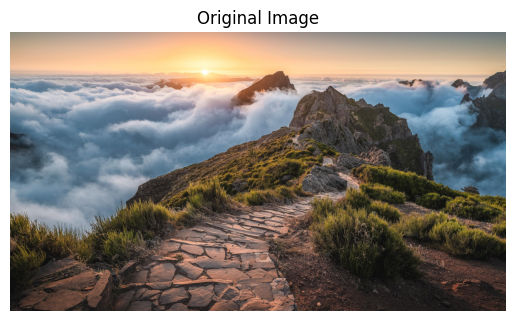

In [2]:
uploaded = files.upload()

image_path = next(iter(uploaded))
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Unable to load image. Upload a valid image.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [4]:
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

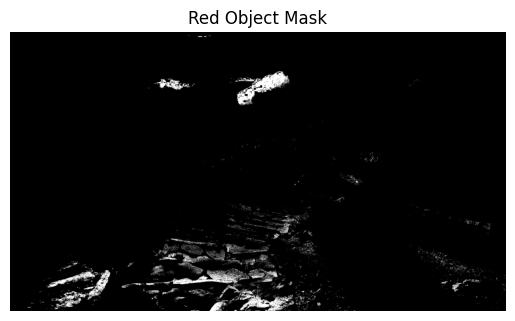

In [5]:
lower_red1 = np.array([0, 100, 100])
upper_red1 = np.array([10, 255, 255])

lower_red2 = np.array([170, 100, 100])
upper_red2 = np.array([180, 255, 255])

mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(hsv, lower_red2, upper_red2)

mask = cv2.bitwise_or(mask1, mask2)

plt.imshow(mask, cmap="gray")
plt.title("Red Object Mask")
plt.axis("off")
plt.show()

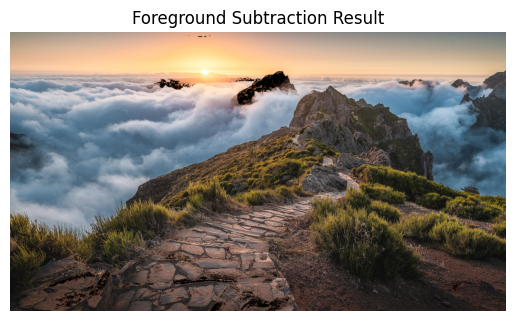

In [6]:
foreground_mask = cv2.bitwise_not(mask)

result = cv2.bitwise_and(
    image,
    image,
    mask=foreground_mask
)

result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

plt.imshow(result_rgb)
plt.title("Foreground Subtraction Result")
plt.axis("off")
plt.show()

In [7]:
output_path = "foreground_subtraction_output.jpg"

cv2.imwrite(output_path, result)

files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>